# Assignment 5: Puzzle State Simulation & Quantum Coin Flip

In [1]:
%pip install -q qiskit qiskit-aer matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


=== 1. Puzzle State Simulation Demo ===
Most probable measured state: 000010011011101100
Simulation completed successfully!

=== 2. Quantum Coin Flip Demonstration ===
Coin Flip Results:
  Heads (0): 490 (49.00%)
  Tails (1): 510 (51.00%)


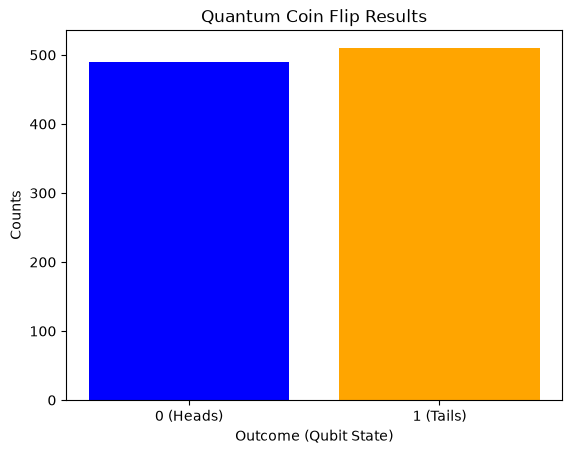

In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt

def run_puzzle_state_demo():
    print("=== 1. Puzzle State Simulation Demo ===")
    initial_state = [2, 5, 3, 1, 8, 6, 4, 7, None]
    goal_state = [1, 2, 3, 4, 5, 6, 7, 8, None]

    qc = QuantumCircuit(18, 18)

    for i, tile in enumerate(initial_state):
        if tile is not None:
            qc.x(i)

    for i, tile in enumerate(goal_state):
        if tile is not None:
            if tile in initial_state:
                initial_index = initial_state.index(tile)
                target_index = goal_state.index(tile)
                qc.swap(i, initial_index + 9)
                qc.swap(i, target_index + 9)

    qc.measure(range(18), range(18))

    backend = AerSimulator()
    compiled_qc = transpile(qc, backend)
    job = backend.run(compiled_qc, shots=1024)
    counts = job.result().get_counts()

    max_state = max(counts, key=counts.get)
    print(f"Most probable measured state: {max_state}")
    print("Simulation completed successfully!\n")

def run_quantum_coin_flip():
    print("=== 2. Quantum Coin Flip Demonstration ===")
    qc = QuantumCircuit(1, 1)
    qc.h(0)
    qc.measure(0, 0)

    backend = AerSimulator()
    compiled_qc = transpile(qc, backend)
    num_shots = 1000
    job = backend.run(compiled_qc, shots=num_shots)
    counts = job.result().get_counts()

    print("Coin Flip Results:")
    for outcome, count in counts.items():
        state_label = "Heads (0)" if outcome == '0' else "Tails (1)"
        print(f"  {state_label}: {count} ({count/num_shots*100:.2f}%)")

    outcomes = list(counts.keys())
    counts_list = list(counts.values())
    plt.bar(outcomes, counts_list, color=['blue', 'orange'])
    plt.xlabel('Outcome (Qubit State)')
    plt.ylabel('Counts')
    plt.title('Quantum Coin Flip Results')
    plt.xticks(outcomes, ['0 (Heads)', '1 (Tails)'])
    plt.show()

if __name__ == '__main__':
    run_puzzle_state_demo()
    run_quantum_coin_flip()